# Import packages

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Read data

## Read LVVI3 data

In [5]:
df_or = pd.read_pickle('../../data/LVVI3/LVVI3_or_en.pkl').assign(source='or')
df_nbt = pd.read_pickle('../../data/LVVI3/LVVI3_nbt_en.pkl').assign(source='nbt')
df = pd.concat([df_or, df_nbt], ignore_index=True)

print(f'Outdoor recreation data count: {df_or.shape[0]}')
print(f'Nature-based tourism data count: {df_nbt.shape[0]}')

Outdoor recreation data count: 165
Nature-based tourism data count: 286


In [8]:
# Map demographic variables
gender_map = {1: 'Male', 2: 'Female', 3: 'Other'}
df['gender'] = df['A1_gender'].map(gender_map)

age_map = {
    1: '<16',
    2: '16-24',
    3: '25-34',
    4: '35-44',
    5: '45-54',
    6: '55-64',
    7: '65-74',
    8: '>75'}
df['age'] = df['A2_age'].map(age_map)

## Read LVVI3 activities for postprocessing

In [13]:
# Read LVVI3 activities for postprocessing
df_activities_post_origin = pd.read_csv('../../data/YouTube/LVVI3_activities_inference_postprocessing.csv')
df_activities_post = df_activities_post_origin[df_activities_post_origin['type']=='survey_activity']
ls_activities_post = df_activities_post['activity'].unique().tolist()
ls_subactivities_post = df_activities_post['sub_activity'].unique().tolist()
ls_activities_post = list(set(ls_activities_post + ls_subactivities_post))

# Rename LVVI3 activities to align with activities for postprocessing

In [16]:
ls_sub_activities = df.sub_activity.unique().tolist()
[act for act in ls_sub_activities if act not in ls_activities_post]

['Orienteering for recreational fitness',
 'Cross-country skiing on prepared runs (less than 20 km)',
 'Cross-country skiing on mainly untracked terrain',
 'At least 20 km or up to 12 hours cross-country skiing',
 'Snowboarding on slopes',
 'Downhill skiing on slopes',
 'Nature observation (e.g. rafting)',
 'Nature photography, painting',
 'Bird watching, counting, marking or feeding',
 'Picking wild berries',
 'Birding, small game hunting or other hunting',
 'Picnics',
 'Sunbathing or lounging elsewhere in nature',
 'Dog walking in nature',
 'Jogging or running on walking paths and outdoor trails',
 'Trail or cross-country running',
 'Other recreational cycling or leisure biking',
 'Cycling tour of at least 30 km or at least half a day',
 'Other walking for exercise',
 'Hiking at least 10 km',
 'Backcountry or cross-country skiing with overnight stay on a ski trip',
 'Sunbathing, lounging or sightseeing on the beach',
 'Recreational swimming',
 'Canoeing, kayaking',
 'Camping overnigh

In [17]:
df["sub_activity"] = df["sub_activity"].replace("Orienteering for recreational fitness", "Orienteering")
df["sub_activity"] = df["sub_activity"].replace("Cross-country skiing on prepared runs (less than 20 km)", "Cross-country skiing")
df["sub_activity"] = df["sub_activity"].replace("Cross-country skiing on mainly untracked terrain", "Cross-country skiing")
df["sub_activity"] = df["sub_activity"].replace("At least 20 km or up to 12 hours cross-country skiing", "Cross-country skiing")
df["sub_activity"] = df["sub_activity"].replace("Snowboarding on slopes", "Snowboarding")
df["sub_activity"] = df["sub_activity"].replace("Downhill skiing on slopes", "Downhill skiing")
df["sub_activity"] = df["sub_activity"].replace("Nature observation (e.g. rafting)", "Nature observation")
df["sub_activity"] = df["sub_activity"].replace("Nature photography, painting", "Nature photography")
df["sub_activity"] = df["sub_activity"].replace("Bird watching, counting, marking or feeding", "Bird watching")
df["sub_activity"] = df["sub_activity"].replace("Picking wild berries", "Berry picking")
df["sub_activity"] = df["sub_activity"].replace("Birding, small game hunting or other hunting", "Bird hunting")
df["sub_activity"] = df["sub_activity"].replace("Picnics", "Picnicking")
df["sub_activity"] = df["sub_activity"].replace("Sunbathing or lounging elsewhere in nature", "Sunbathing")
df["sub_activity"] = df["sub_activity"].replace("Dog walking in nature", "Dog walking")
df["sub_activity"] = df["sub_activity"].replace("Jogging or running on walking paths and outdoor trails", "Jogging")
df["sub_activity"] = df["sub_activity"].replace("Trail or cross-country running", "Running")
df["sub_activity"] = df["sub_activity"].replace("Other recreational cycling or leisure biking", "Cycling")
df["sub_activity"] = df["sub_activity"].replace("Cycling tour of at least 30 km or at least half a day", "Cycling")
df["sub_activity"] = df["sub_activity"].replace("Other walking for exercise", "Walking")
df["sub_activity"] = df["sub_activity"].replace("Hiking at least 10 km", "Hiking")
df["sub_activity"] = df["sub_activity"].replace("Backcountry or cross-country skiing with overnight stay on a ski trip", "Cross-country skiing")
df["sub_activity"] = df["sub_activity"].replace("Sunbathing, lounging or sightseeing on the beach", "Sunbathing")
df["sub_activity"] = df["sub_activity"].replace("Recreational swimming", "Swimming")
df["sub_activity"] = df["sub_activity"].replace("Canoeing, kayaking", "Canoeing")
df["sub_activity"] = df["sub_activity"].replace("Camping overnight on a camping site", "Camping")
df["sub_activity"] = df["sub_activity"].replace("Mountain biking mainly on trails", "Mountain biking")
df["sub_activity"] = df["sub_activity"].replace("Overnight hiking", "Hiking")

In [ ]:
# Create a mapping: sub_activity → activity
sub_to_activity = df_activities_post_origin.set_index('sub_activity')['activity'].to_dict()
sub_to_structural_activity = df_activities_post_origin.set_index('sub_activity')['structural_activity'].to_dict()

# Map the 'sub_activity' column to get the corresponding 'activity'
df['activity'] = df['sub_activity'].map(sub_to_activity)
df['structural_activity'] = df['sub_activity'].map(sub_to_structural_activity)

In [23]:
df.to_pickle('../../data/LVVI3/LVVI3_en.pkl')
# df = pd.read_pickle('../../data/LVVI3/LVVI3_en.pkl')

# Visit-based approach

A visit is a temporary configuration of activities, accompanies, motivations, travel behaviors.

Application cases:
- Understanding pressure on sites
- Understanding facility needs
- Understanding conflict between visitor uses
- Designing zoning, infrastructure, and services

## Prepare variables

In [ ]:
# Create two-level activity coding
df["activity_specific"] = df["activity"]

# Define structural activity categories
activity_map = {
    # Light movement / walking
    "Walking": "Light movement / walking",

    # Nature immersion / camping
    "Camping": "Nature immersion / camping",

    # Active outdoor sports
    "Skiing": "Active outdoor sports",
    "Running": "Active outdoor sports",
    "Cycling": "Active outdoor sports",
    "Skating": "Active outdoor sports",
    "Snowmobiling": "Active outdoor sports",

    # Leisure use
    "Outdoor activities with dogs": "Leisure use",
    "Outdoor activities with children": "Leisure use",
    "Picnicking": "Leisure use",
    "Swimming": "Leisure use",
    "Boating": "Leisure use",

    # Nature-dependent extraction
    "Fishing": "Nature-dependent extraction",
    "Hunting": "Nature-dependent extraction",
    "Nature product collection": "Nature-dependent extraction",

    # Nature appreciation
    "Nature photography": "Nature appreciation",

    # Playful recreation
    "Golf": "Playful recreation",
    "Treasure hunting": "Playful recreation",

    # Others
    "Guided tour": "Others",
    "Forest": "Others"
}

df["activity_structural"] = df["activity"].map(activity_map)

df["activity_structural"].value_counts()

activity_structural
Light movement / walking       219
Active outdoor sports           76
Leisure use                     60
Nature-dependent extraction     42
Nature appreciation             19
Nature immersion / camping      17
Playful recreation              13
Others                           5
Name: count, dtype: int64

In [37]:
accompany_map = {
    1.0: "Alone",
    2.0: "With family",
    3.0: "With friends",
    4.0: "With work colleagues/business guests",
    5.0: "With school class/student group",
    6.0: "With club, association",
    7.0: "With other group",
}

df["accompany"] = df["B_2_accompany"].map(accompany_map)

In [41]:
# Select visit-related variables
visit_vars = ['activity_structural', 'accompany']
df_mca = df[visit_vars]

# Make sure variables are categorical
for col in visit_vars:
    df_mca[col] = df_mca[col].astype("category")

C:\Users\leyixu\AppData\Local\Temp\ipykernel_18264\613931504.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_mca[col] = df_mca[col].astype("category")
C:\Users\leyixu\AppData\Local\Temp\ipykernel_18264\613931504.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_mca[col] = df_mca[col].astype("category")


In [12]:
df[df['activity']=='Forest'][['activity', 'sub_activity']]

,activity,sub_activity
249,Forest,Game management


In [ ]:
df[df['activity']=='Guided tour'][['activity', 'sub_activity']]

,activity,sub_activity
165,Guided tour,Guided excursion for a fee
166,Guided tour,Guided excursion for a fee
167,Guided tour,Guided excursion for a fee
168,Guided tour,Group exercise e.g. gymnastics or dance in a p...


## Apply Multiple Correspondence Analysis (MCA) to transform categorical variables into numeri coordinates

In [42]:
# Run MCA
import prince

mca = prince.MCA(
    n_components=5,
    n_iter=10,
    random_state=42
)

mca = mca.fit(df_mca)
mca_coords = mca.transform(df_mca)

In [23]:
# Decide the number of dimensions to retain
mca.percentage_of_variance_

array([9.79280348, 9.20111439, 8.93598082, 8.38619574, 8.18261417])

In [97]:
# Select MCA dimensions for clustering
mca_coords_reduced = mca_coords.iloc[:, :3]
# mca_coords_reduced = mca_coords.iloc[:, :4]

## Determine the number of clusters

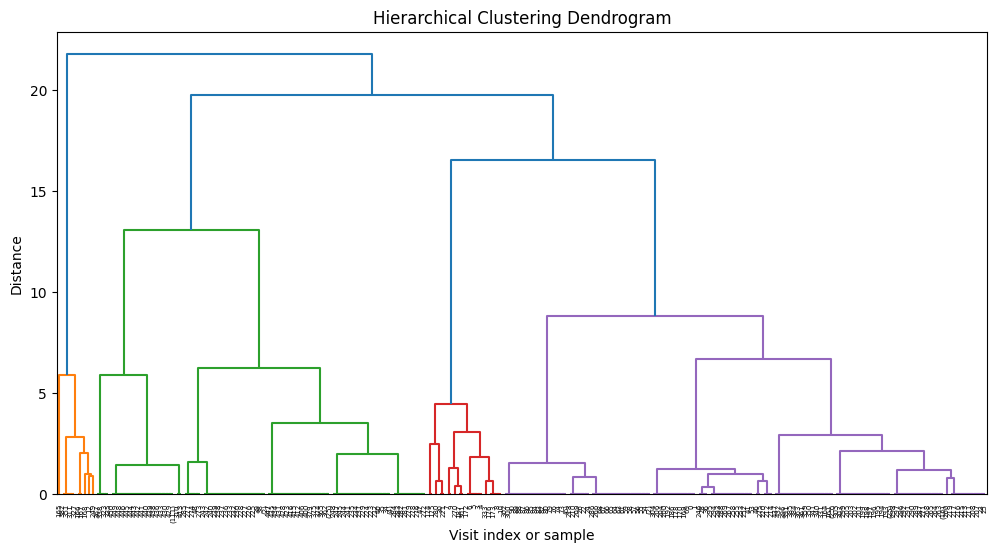

In [98]:
from scipy.cluster.hierarchy import linkage, dendrogram

# Compute linkage matrix (Ward method matches your clustering)
Z = linkage(mca_coords_reduced, method='ward')

# Dendrogram plot
plt.figure(figsize=(12, 6))
dendrogram(Z, truncate_mode='level', p=20, leaf_rotation=90)
plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Visit index or sample')
plt.ylabel('Distance')
plt.show()


In [99]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import AgglomerativeClustering

range_n_clusters = range(2, 10)
for n_clusters in range_n_clusters:
    clusterer = AgglomerativeClustering(n_clusters=n_clusters, linkage='ward')
    cluster_labels = clusterer.fit_predict(mca_coords_reduced)
    silhouette_avg = silhouette_score(mca_coords_reduced, cluster_labels)
    print(f"n_clusters = {n_clusters}, silhouette_score = {silhouette_avg:.3f}")


n_clusters = 2, silhouette_score = 0.745
n_clusters = 3, silhouette_score = 0.456
n_clusters = 4, silhouette_score = 0.510
n_clusters = 5, silhouette_score = 0.592
n_clusters = 6, silhouette_score = 0.649
n_clusters = 7, silhouette_score = 0.695
n_clusters = 8, silhouette_score = 0.735
n_clusters = 9, silhouette_score = 0.758


## Apply hierarchical clustering

In [100]:
# Apply hierarchical clustering
from sklearn.cluster import AgglomerativeClustering

# Choose 5 clusters as initial guess
clusterer = AgglomerativeClustering(n_clusters=5, linkage='ward')
df['visit_type'] = clusterer.fit_predict(mca_coords_reduced)

In [101]:
df['visit_type'].value_counts()

visit_type
0    196
1    133
2     92
3     20
4     10
Name: count, dtype: int64

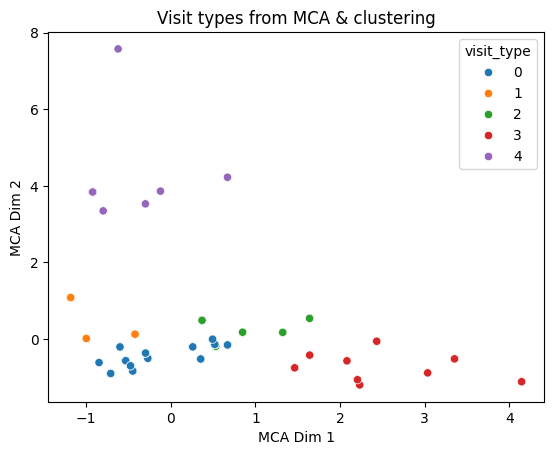

In [102]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.scatterplot(x=mca_coords_reduced.iloc[:,0],
                y=mca_coords_reduced.iloc[:,1],
                hue=df['visit_type'],
                palette='tab10')
plt.xlabel('MCA Dim 1')
plt.ylabel('MCA Dim 2')
plt.title('Visit types from MCA & clustering')
plt.show()


## Profile visit type

### Activities

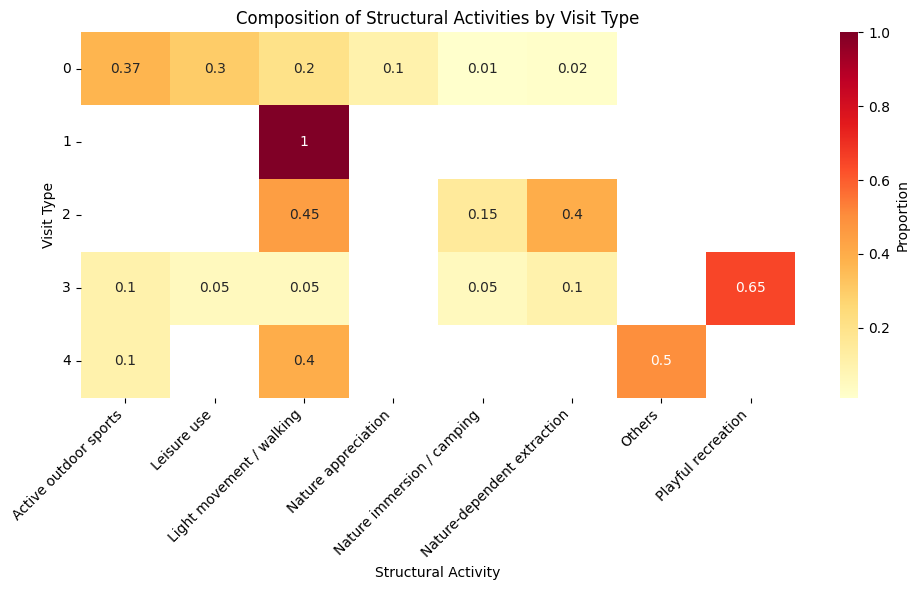

In [ ]:
# Compute normalized composition of activities by visit type
activity_profile = df.groupby('visit_type')['activity_structural'].value_counts(normalize=True).unstack().round(2)

plt.figure(figsize=(10, 6))
sns.heatmap(activity_profile, annot=True, cmap='YlOrRd', cbar_kws={'label': 'Proportion'})
plt.title('Composition of Structural Activities by Visit Type')
plt.ylabel('Visit Type')
plt.xlabel('Structural Activity')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

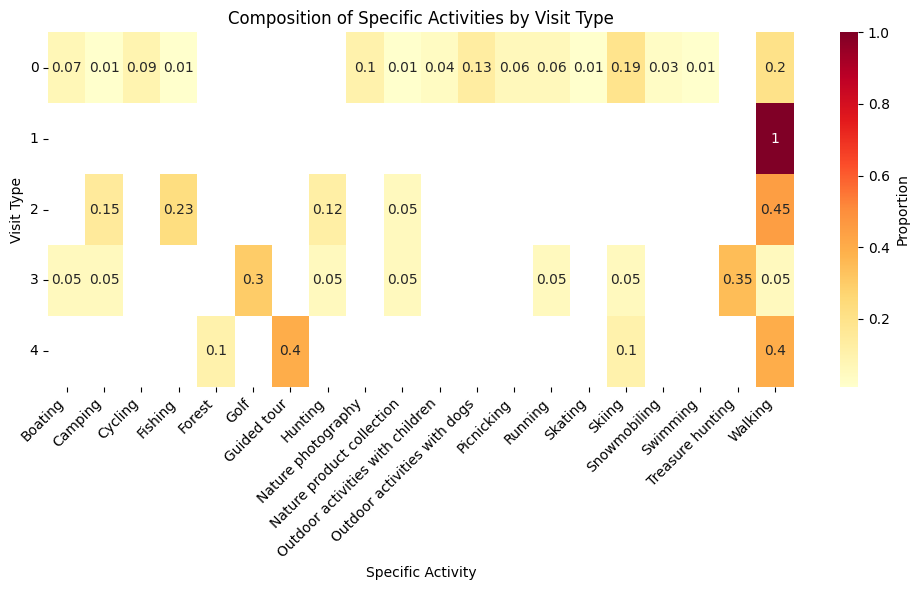

In [105]:
# Compute normalized composition of activities by visit type
activity_specific_profile = df.groupby('visit_type')['activity_specific'].value_counts(normalize=True).unstack().round(2)

plt.figure(figsize=(10, 6))
sns.heatmap(activity_specific_profile, annot=True, cmap='YlOrRd', cbar_kws={'label': 'Proportion'})
plt.title('Composition of Specific Activities by Visit Type')
plt.ylabel('Visit Type')
plt.xlabel('Specific Activity')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Accompany patterns

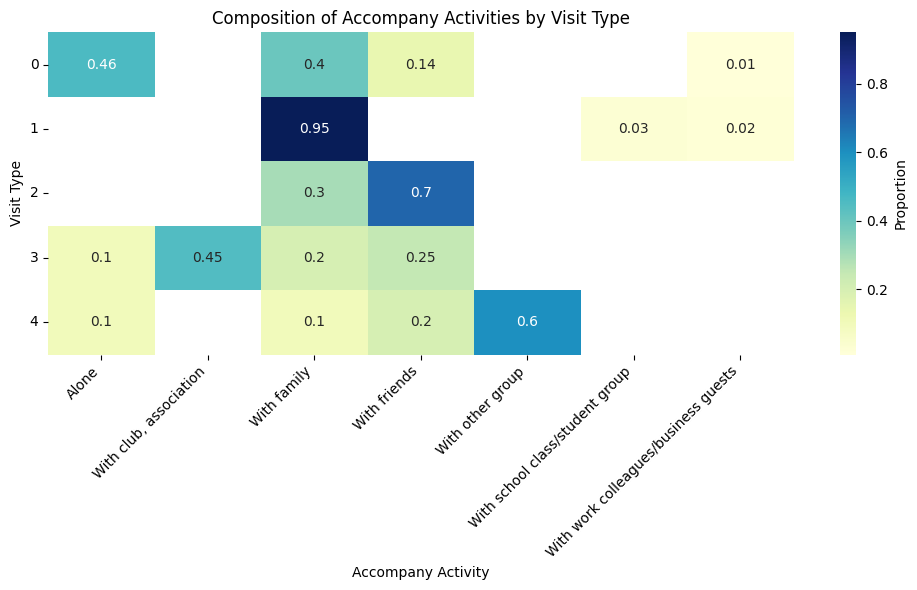

In [75]:
# Compute normalized composition of accompany patterns by visit type
accompany_profile = df.groupby('visit_type')['accompany'].value_counts(normalize=True).unstack().round(2)

plt.figure(figsize=(10, 6))
sns.heatmap(accompany_profile, annot=True, cmap='YlGnBu', cbar_kws={'label': 'Proportion'})
plt.title('Composition of Accompany Activities by Visit Type')
plt.ylabel('Visit Type')
plt.xlabel('Accompany Activity')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Motivations

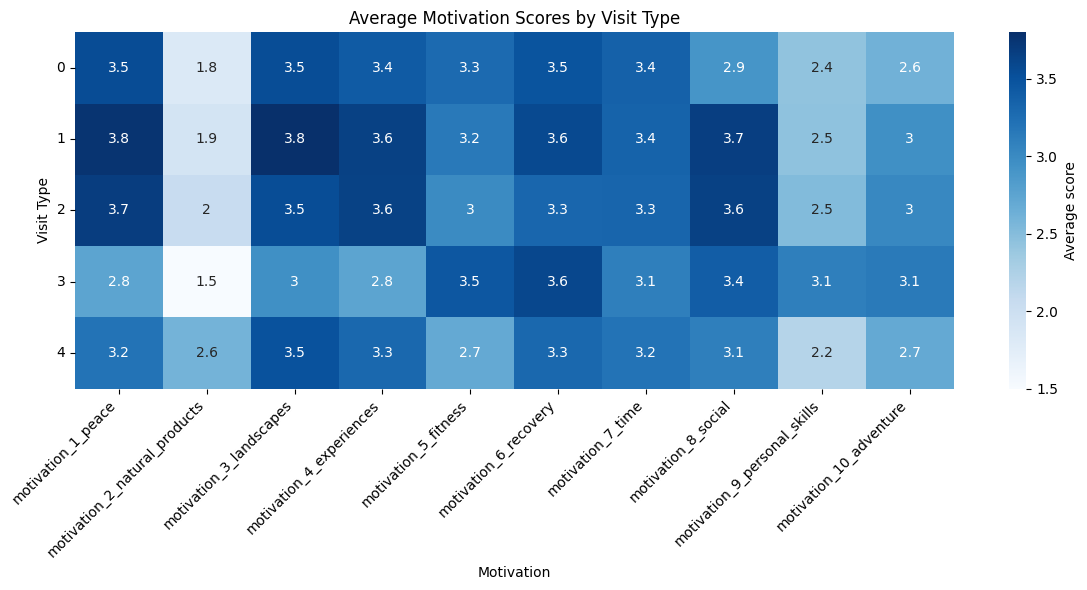

In [122]:
# Motivation columns
motivation_cols = [
    'motivation_1_peace',
    'motivation_2_natural_products',
    'motivation_3_landscapes',
    'motivation_4_experiences',
    'motivation_5_fitness',
    'motivation_6_recovery',
    'motivation_7_time',
    'motivation_8_social',
    'motivation_9_personal_skills',
    'motivation_10_adventure'
]

# Compute averaged values of motivations by visit type
motivation_avg = df.groupby('visit_type')[motivation_cols].mean().round(2)

plt.figure(figsize=(12, 6))
sns.heatmap(motivation_avg, annot=True, cmap='Blues', cbar_kws={'label': 'Average score'})
plt.title('Average Motivation Scores by Visit Type')
plt.xlabel('Motivation')
plt.ylabel('Visit Type')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Gender

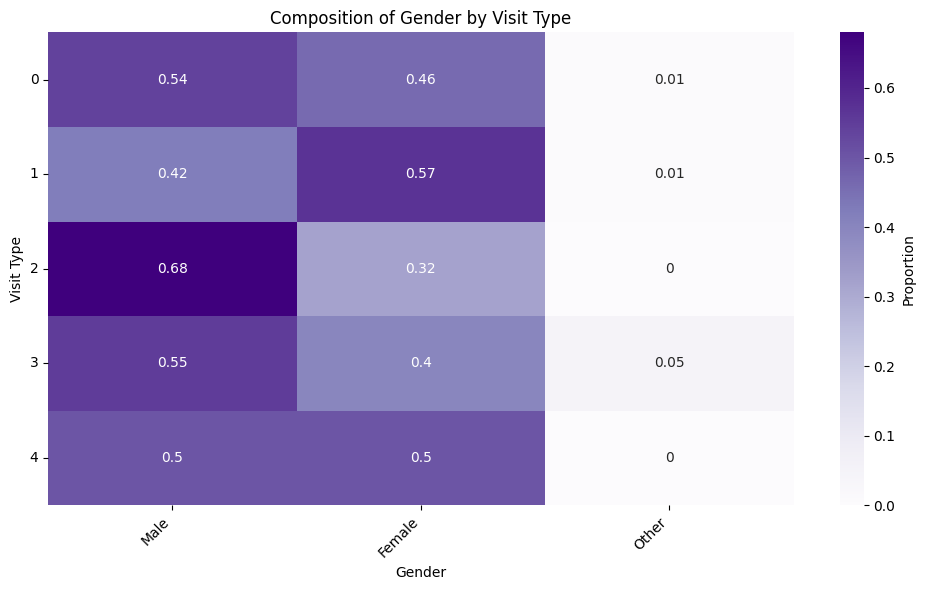

In [147]:
# Compute Percent of each gender by visit type
gender_counts = df.groupby('visit_type')['gender'].value_counts().unstack(fill_value=0)
gender_pct = gender_counts.div(gender_counts.sum(axis=1), axis=0).round(2)
gender_pct = gender_pct[['Male', 'Female', 'Other']]
gender_pct

plt.figure(figsize=(10, 6))
sns.heatmap(gender_pct, annot=True, cmap='Purples', cbar_kws={'label': 'Proportion'})
plt.title('Composition of Gender by Visit Type')
plt.ylabel('Visit Type')
plt.xlabel('Gender')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Age

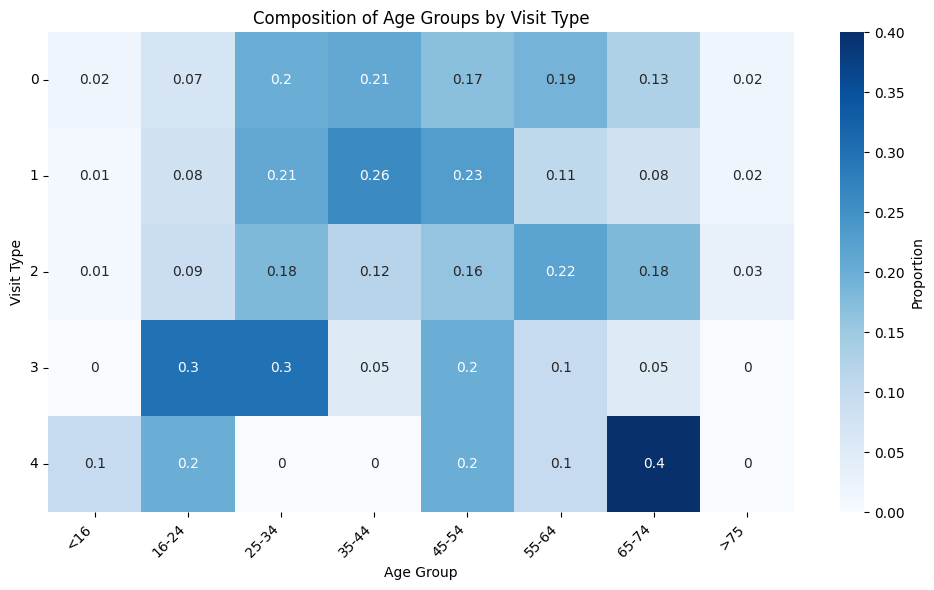

In [150]:
# Compute Percent of each age group by visit type
age_counts = df.groupby('visit_type')['age'].value_counts().unstack(fill_value=0)
age_pct = age_counts.div(age_counts.sum(axis=1), axis=0).round(2)
age_pct = age_pct[['<16', '16-24', '25-34', '35-44', '45-54', '55-64', '65-74', '>75']]
age_pct

plt.figure(figsize=(10, 6))
sns.heatmap(age_pct, annot=True, cmap='Blues', cbar_kws={'label': 'Proportion'})
plt.title('Composition of Age Groups by Visit Type')
plt.ylabel('Visit Type')
plt.xlabel('Age Group')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Travel time

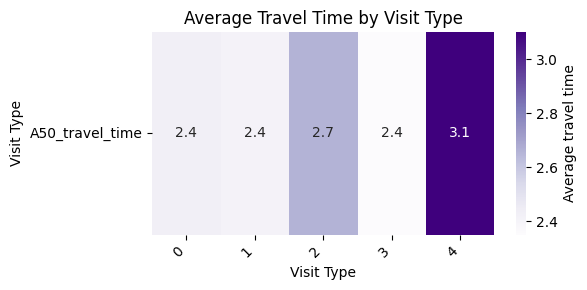

In [108]:
# Compute averaged values of travel time by visit type
travel_time_avg = df.groupby('visit_type')['A50_travel_time'].mean().round(2)

plt.figure(figsize=(6, 3))
sns.heatmap(travel_time_avg.to_frame().T, annot=True, cmap='Purples', cbar_kws={'label': 'Average travel time'})
plt.title('Average Travel Time by Visit Type')
plt.xlabel('Visit Type')
plt.ylabel('Visit Type')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Travel distance

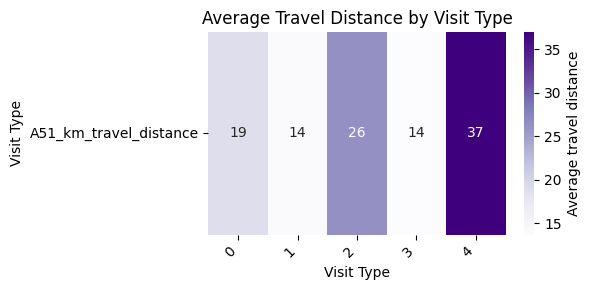

In [109]:
# Compute averaged values of travel distance by visit type
travel_distance_avg = df.groupby('visit_type')['A51_km_travel_distance'].mean().round(2)

plt.figure(figsize=(6, 3))
sns.heatmap(travel_distance_avg.to_frame().T, annot=True, cmap='Purples', cbar_kws={'label': 'Average travel distance'})
plt.title('Average Travel Distance by Visit Type')
plt.xlabel('Visit Type')
plt.ylabel('Visit Type')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Areas

In [129]:
destination_map = {
    1.0: 'Municipal outdoor recreation area or trail',
    2.0: 'State recreation or fishing area or trail',
    3.0: 'National park',
    4.0: 'Wilderness area',
    5.0: 'State nature reserve',
    6.0: 'Municipal nature reserve',
    7.0: 'Other nature reserve',
    8.0: 'Environment of own farm or forestry holding',
    9.0: 'Own recreational dwelling and its surroundings',
    10.0: 'Private forest, water area, etc.',
    11.0: 'State-owned forest, water area, etc.',
    12.0: 'Outdoor recreation area provided by a company or association',
    13.0: 'Rural tourism destination',
    14.0: 'Don\'t know'
}

df['area_destination'] = df['area_destination'].map(destination_map)

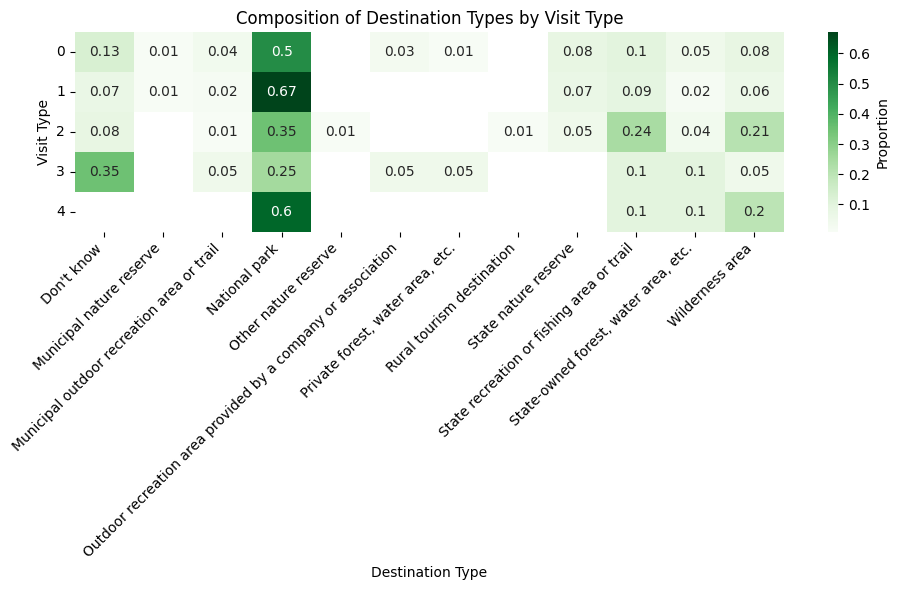

In [134]:
# Compute normalized composition of destination types by visit type
destination_profile = df.groupby('visit_type')['area_destination'].value_counts(normalize=True).unstack().round(2)

plt.figure(figsize=(10, 6))
sns.heatmap(destination_profile, annot=True, cmap='Greens', cbar_kws={'label': 'Proportion'})
plt.title('Composition of Destination Types by Visit Type')
plt.ylabel('Visit Type')
plt.xlabel('Destination Type')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

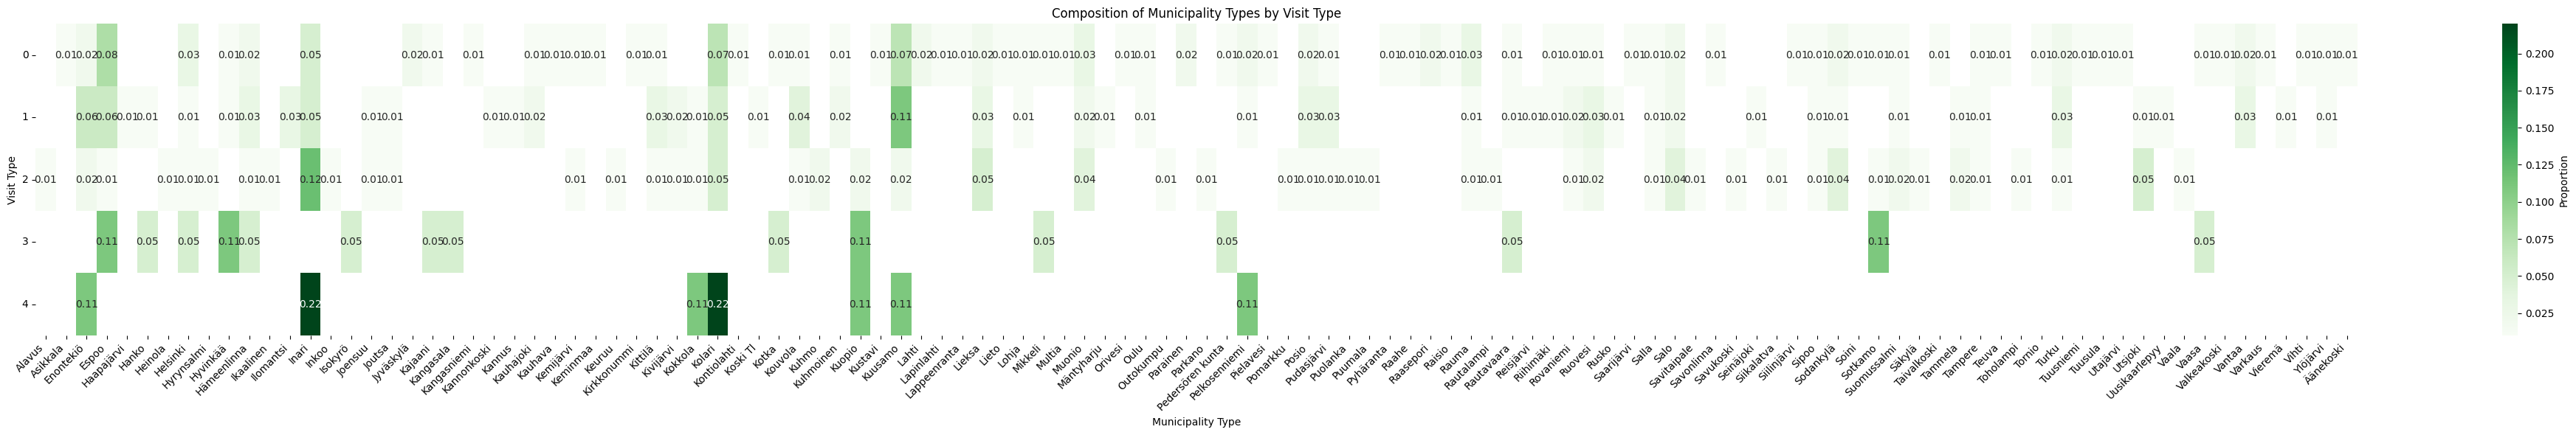

In [142]:
# Compute normalized composition of municipality by visit type
municipality_profile = df.groupby('visit_type')['area_municipality'].value_counts(normalize=True).unstack().round(2)

plt.figure(figsize=(40, 6))
sns.heatmap(municipality_profile, annot=True, cmap='Greens', cbar_kws={'label': 'Proportion'})
plt.title('Composition of Municipality Types by Visit Type')
plt.ylabel('Visit Type')
plt.xlabel('Municipality Type')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Opionins

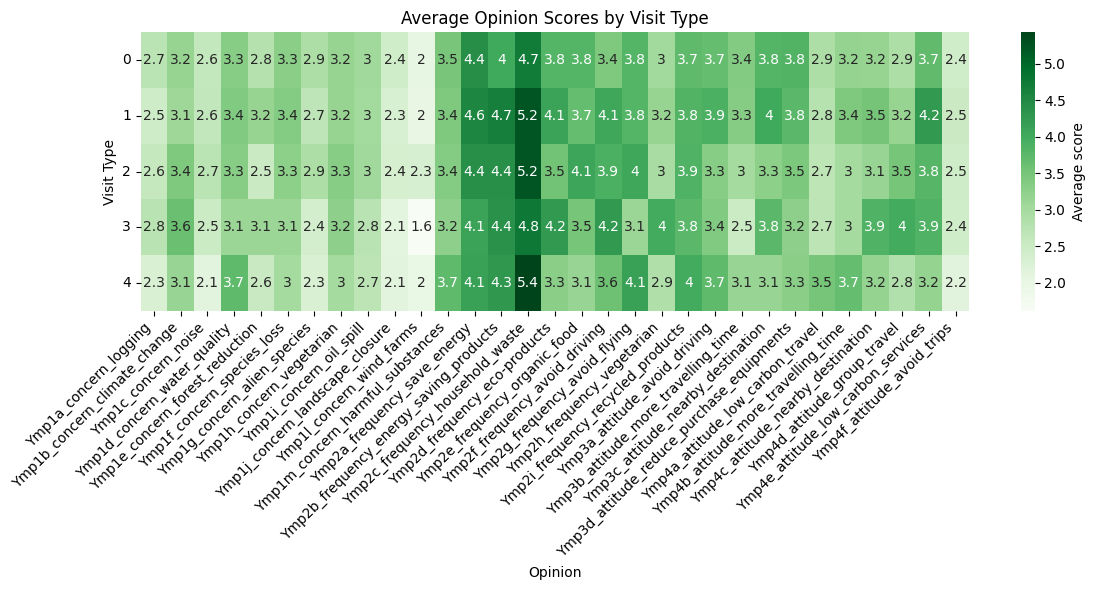

In [125]:
opinion_cols = [
    'Ymp1a_concern_logging', 
    'Ymp1b_concern_climate_change', 
    'Ymp1c_concern_noise',
    'Ymp1d_concern_water_quality',
    'Ymp1e_concern_forest_reduction',
    'Ymp1f_concern_species_loss',
    'Ymp1g_concern_alien_species',
    'Ymp1h_concern_vegetarian',
    'Ymp1i_concern_oil_spill',
    'Ymp1j_concern_landscape_closure',
    'Ymp1l_concern_wind_farms',
    'Ymp1m_concern_harmful_substances',
    'Ymp2a_frequency_save_energy',
    'Ymp2b_frequency_energy_saving_products',
    'Ymp2c_frequency_household_waste',
    'Ymp2d_frequency_eco-products',
    'Ymp2e_frequency_organic_food',
    'Ymp2f_frequency_avoid_driving',
    'Ymp2g_frequency_avoid_flying',
    'Ymp2h_frequency_vegetarian',
    'Ymp2i_frequency_recycled_products',
    'Ymp3a_attitude_avoid_driving',
    'Ymp3b_attitude_more_travelling_time',
    'Ymp3c_attitude_nearby_destination',
    'Ymp3d_attitude_reduce_purchase_equipments',
    'Ymp4a_attitude_low_carbon_travel',
    'Ymp4b_attitude_more_travelling_time',
    'Ymp4c_attitude_nearby_destination',
    'Ymp4d_attitude_group_travel',
    'Ymp4e_attitude_low_carbon_services',
    'Ymp4f_attitude_avoid_trips'
]

# Compute averaged values of opinions by visit type
opinion_avg = df.groupby('visit_type')[opinion_cols].mean().round(2)

plt.figure(figsize=(12, 6))
sns.heatmap(opinion_avg, annot=True, cmap='Greens', cbar_kws={'label': 'Average score'})
plt.title('Average Opinion Scores by Visit Type')
plt.xlabel('Opinion')
plt.ylabel('Visit Type')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Visitor-based approach

A visitor type is a relatively stable configuration of demographics, recreational preferences, ...

Application cases:
- Long-term visitor management
- Communication strategies
- Equity and access questions
- Understanding who is underrepresented